In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv(
    "../data/ecommerce_orders_cleaned.csv",
    parse_dates=['order_date']
)

df.head()

,order_id,order_date,customer_id,city,age,gender,product_category,unit_price_inr,quantity,discount_percent,shipping_fee_inr,gross_amount_inr,discount_amount_inr,net_amount_inr,payment_method,sales_channel,order_status,delivery_days,customer_rating
0,ORD000001,2024-03-06,CUST00048,Mumbai,21,Male,Fashion,3071.33,4,15,120,12285.32,1842.80,10562.52,Credit Card,Website,Delivered,1.0,4.0
1,ORD000002,2025-07-18,CUST03076,Ahmedabad,41,Female,Beauty,2111.06,2,20,60,4222.12,844.42,3437.70,Net Banking,Marketplace,Delivered,1.0,5.0
2,ORD000003,2025-04-22,CUST01672,Mumbai,32,Female,Books,539.70,4,15,40,2158.80,323.82,1874.98,Cash on Delivery,Mobile App,Delivered,5.0,4.0
3,ORD000004,2024-11-16,CUST00916,Kolkata,50,Female,Electronics,4327.17,1,10,120,4327.17,432.72,4014.45,Cash on Delivery,Marketplace,Delivered,1.0,1.0
4,ORD000005,2024-11-12,CUST02411,Kochi,55,Female,Electronics,22532.39,1,0,0,22532.39,0.00,22532.39,UPI,Marketplace,Delivered,6.0,5.0


In [3]:
print("Shape:", df.shape)
print("Date range:", df['order_date'].min(), "to", df['order_date'].max())

Shape: (10000, 19)
Date range: 2024-01-01 00:00:00 to 2025-12-30 00:00:00


In [4]:
print(df['order_status'].value_counts())

delivered_df = df[df['order_status'] == 'Delivered'].copy()

print("Total delivered orders:", len(delivered_df))

print(
    "Total delivered-order net amount:",
    delivered_df['net_amount_inr'].sum()
)

order_status
Delivered    8593
Cancelled     911
Returned      496
Name: count, dtype: int64
Total delivered orders: 8593
Total delivered-order net amount: 64078683.81


In [5]:
df['order_date'].min()
df['order_date'].max()

Timestamp('2025-12-30 00:00:00')

In [6]:
df['order_status'].value_counts(normalize=True) * 100

order_status
Delivered    85.93
Cancelled     9.11
Returned      4.96
Name: proportion, dtype: float64

In [7]:
delivered_df['month'] = (
    delivered_df['order_date'].dt.to_period('M')
)

In [8]:
monthly_sales = (
    delivered_df.groupby('month')['net_amount_inr']
    .sum()
    .reset_index()
)

monthly_sales['month'] = monthly_sales['month'].astype(str)

monthly_sales

,month,net_amount_inr
0,2024-01,2430494.38
1,2024-02,2532082.37
2,2024-03,2622154.66
3,2024-04,2522797.27
4,2024-05,2888746.68
5,2024-06,2570756.96
6,2024-07,2636475.21
7,2024-08,3106073.72
8,2024-09,2735899.43
9,2024-10,2764945.47


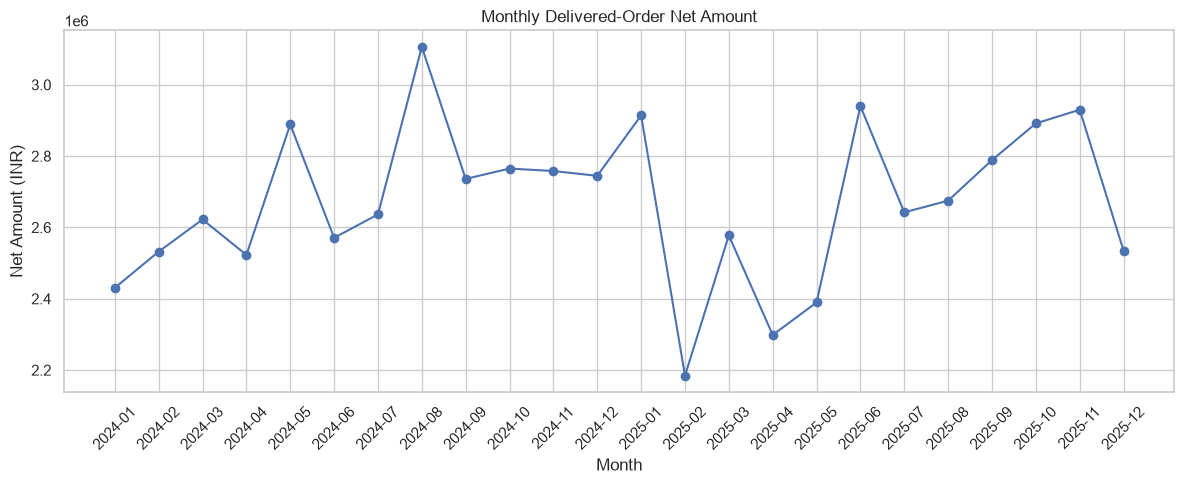

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales['month'],
    monthly_sales['net_amount_inr'],
    marker='o'
)

plt.title('Monthly Delivered-Order Net Amount')
plt.xlabel('Month')
plt.ylabel('Net Amount (INR)')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
print("First order:", df['order_date'].min())
print("Last order:", df['order_date'].max())

First order: 2024-01-01 00:00:00
Last order: 2025-12-30 00:00:00


In [11]:
monthly_sales.sort_values(
    'net_amount_inr',
    ascending=False
).head(5)

,month,net_amount_inr
7,2024-08,3106073.72
17,2025-06,2939924.85
22,2025-11,2929842.70
12,2025-01,2914097.77
21,2025-10,2891576.59


In [12]:
monthly_sales.sort_values(
    'net_amount_inr',
    ascending=True
).head(5)

,month,net_amount_inr
13,2025-02,2184510.69
15,2025-04,2298337.88
16,2025-05,2389504.28
0,2024-01,2430494.38
3,2024-04,2522797.27


In [13]:
category_sales = (
    delivered_df.groupby('product_category')['net_amount_inr']
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

product_category
Electronics       37244627.87
Home & Kitchen    10413246.83
Fashion            7456322.04
Sports             5021986.18
Beauty             2721842.08
Books              1220658.81
Name: net_amount_inr, dtype: float64


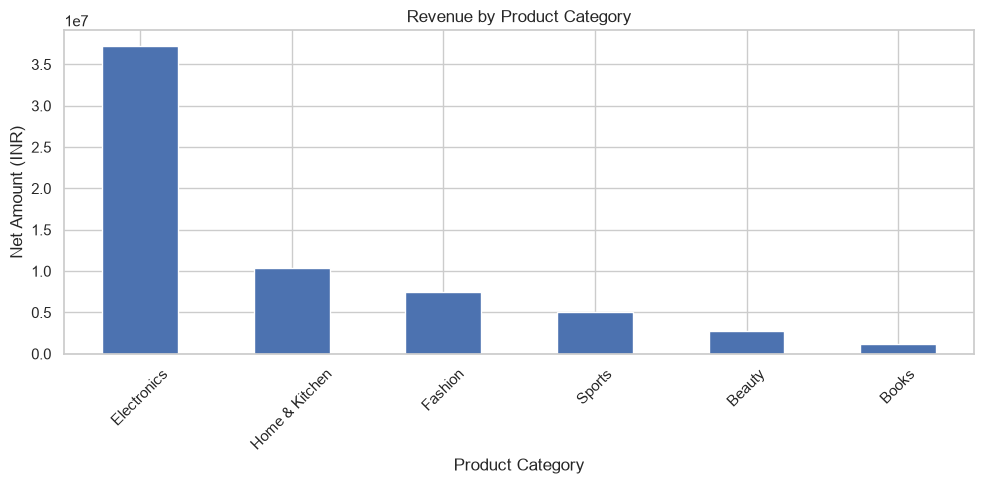

In [14]:
plt.figure(figsize=(10, 5))

category_sales.plot(kind='bar')

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Net Amount (INR)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:

category_analysis = delivered_df.groupby('product_category').agg(
    total_orders=('order_id', 'count'),
    total_revenue=('net_amount_inr', 'sum'),
    average_order_value=('net_amount_inr', 'mean')
).sort_values('total_revenue', ascending=False)

category_analysis

,total_orders,total_revenue,average_order_value
product_category,,,
Electronics,1714,37244627.87,21729.654533
Home & Kitchen,1530,10413246.83,6806.043680
Fashion,2073,7456322.04,3596.875080
Sports,997,5021986.18,5037.097472
Beauty,1272,2721842.08,2139.812956
Books,1007,1220658.81,1212.173595


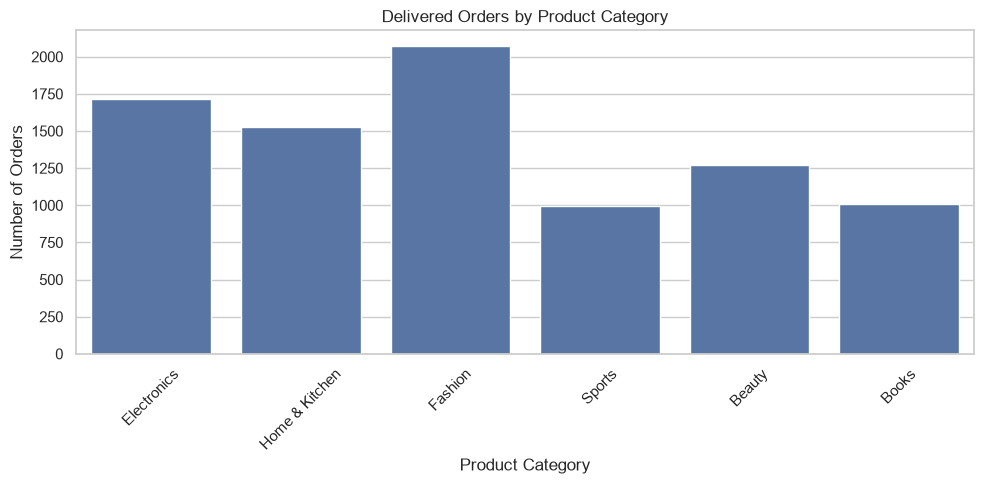

In [16]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_analysis.reset_index(),
    x='product_category',
    y='total_orders'
)

plt.title('Delivered Orders by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
city_analysis = delivered_df.groupby('city').agg(
    total_orders=('order_id', 'count'),
    total_revenue=('net_amount_inr', 'sum'),
    average_order_value=('net_amount_inr', 'mean')
).sort_values('total_revenue', ascending=False)

city_analysis

,total_orders,total_revenue,average_order_value
city,,,
Pune,894,7082457.66,7922.212148
Mumbai,848,6861239.01,8091.083738
Delhi,893,6713977.83,7518.452217
Chennai,879,6711251.55,7635.098464
Jaipur,870,6529768.02,7505.480483
Kochi,862,6400690.56,7425.395081
Bengaluru,856,6206419.35,7250.489895
Ahmedabad,830,5961818.01,7182.913265
Hyderabad,833,5808221.07,6972.654346


In [18]:
gender_analysis = delivered_df.groupby('gender').agg(
    total_orders=('order_id', 'count'),
    total_revenue=('net_amount_inr', 'sum'),
    average_order_value=('net_amount_inr', 'mean')
)

gender_analysis

,total_orders,total_revenue,average_order_value
gender,,,
Female,4138,30812013.20,7446.112421
Male,4193,31376324.96,7483.025271
Other,262,1890345.65,7215.059733


In [19]:
customer_analysis = delivered_df.groupby('customer_id').agg(
    total_orders=('order_id', 'count'),
    total_spent=('net_amount_inr', 'sum'),
    average_order_value=('net_amount_inr', 'mean')
)

customer_analysis.describe()

,total_orders,total_spent,average_order_value
count,2978.000000,2978.000000,2978.000000
mean,2.885494,21517.355208,7488.409401
std,1.505332,21588.759803,7720.279468
min,1.000000,295.460000,295.460000
25%,2.000000,6283.795000,2901.807500
50%,3.000000,14761.975000,5238.571667
75%,4.000000,29532.337500,9332.881667
max,10.000000,239472.150000,170146.320000


In [20]:
top_customers = customer_analysis.sort_values(
    'total_spent',
    ascending=False
).head(10)

top_customers

,total_orders,total_spent,average_order_value
customer_id,,,
CUST02416,5,239472.15,47894.430000
CUST02137,1,170146.32,170146.320000
CUST00413,6,162160.83,27026.805000
CUST00828,8,148232.27,18529.033750
CUST01707,6,145371.00,24228.500000
CUST00179,3,141066.82,47022.273333
CUST01700,6,140069.26,23344.876667
CUST02808,4,140004.39,35001.097500
CUST00963,4,139115.78,34778.945000


In [21]:
one_time_customers = customer_analysis[
    customer_analysis['total_orders'] == 1
]

repeat_customers = customer_analysis[
    customer_analysis['total_orders'] > 1
]

print("Total customers:", len(customer_analysis))

print("One-time customers:", len(one_time_customers))

print("Repeat customers:", len(repeat_customers))

print(
    "Repeat customer percentage:",
    round(len(repeat_customers) / len(customer_analysis) * 100, 2),
    "%"
)

Total customers: 2978
One-time customers: 556
Repeat customers: 2422
Repeat customer percentage: 81.33 %


## Data Visualization

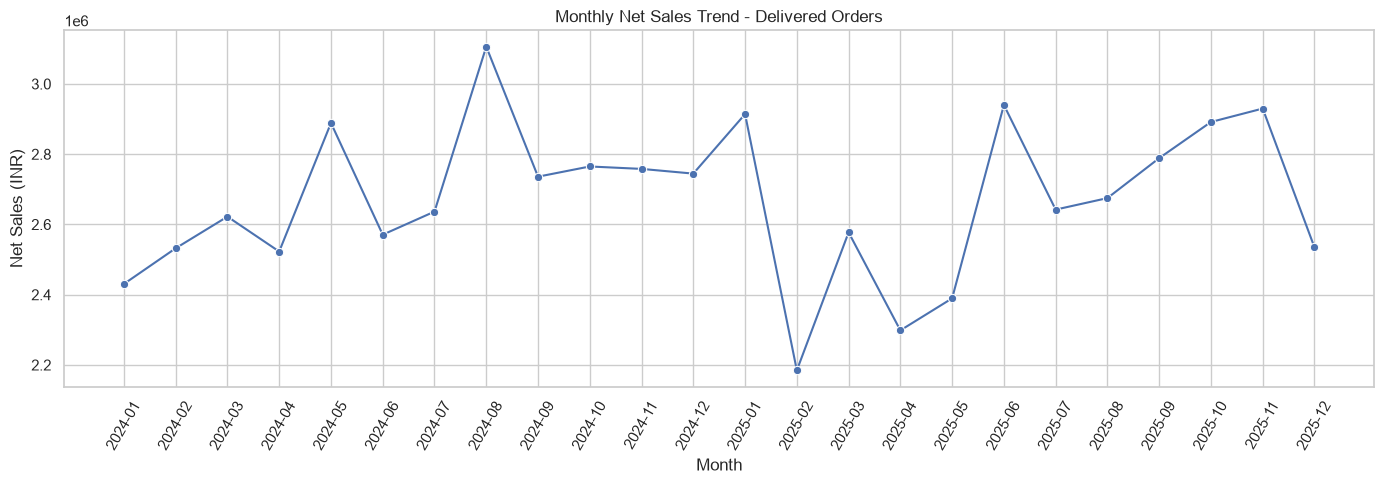

Saved: 01_monthly_sales_trend.png


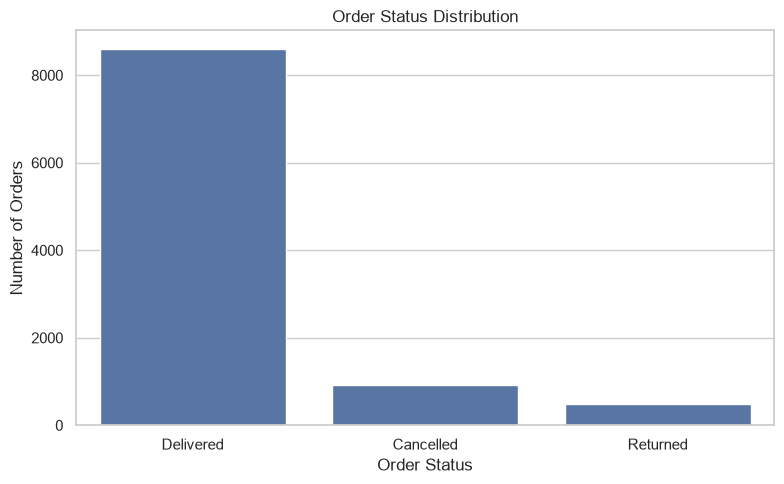

Saved: 02_order_status_distribution.png


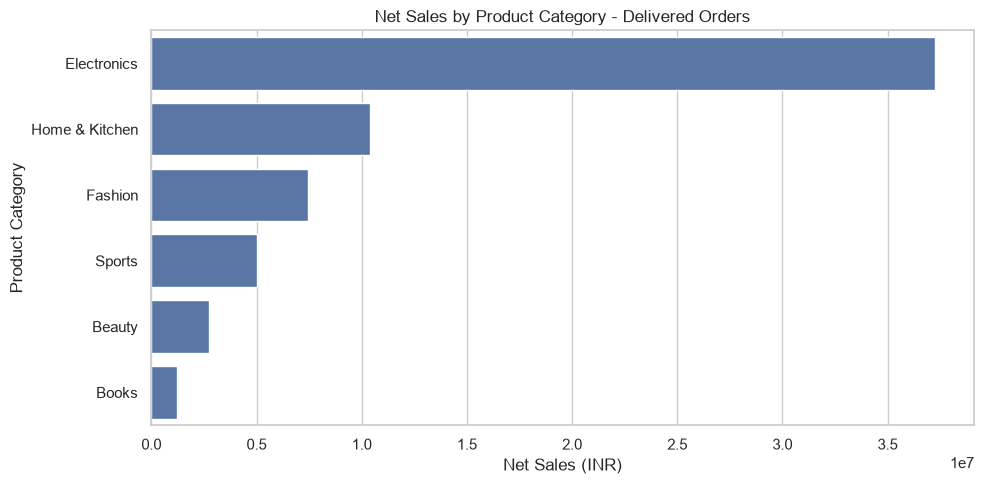

Saved: 03_category_revenue.png


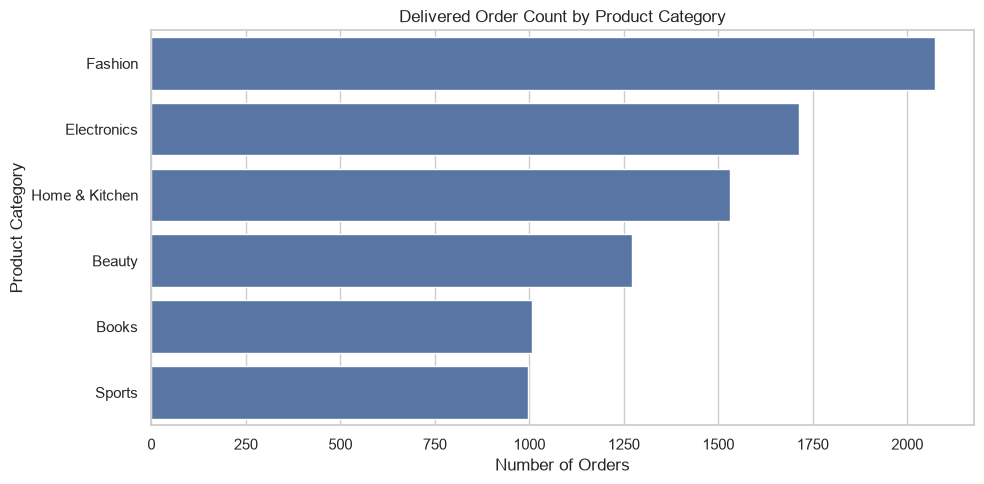

Saved: 04_category_order_count.png


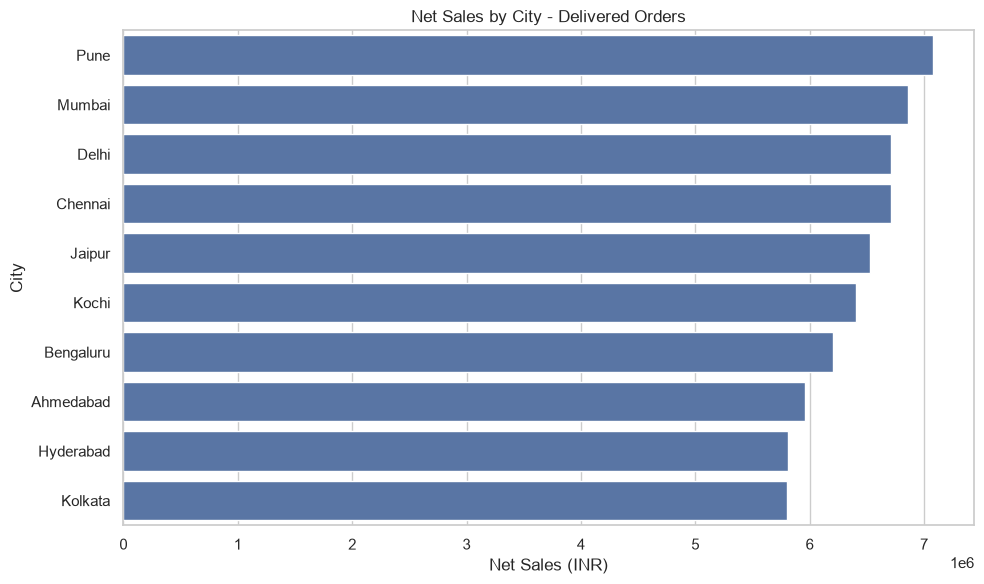

Saved: 05_city_revenue.png


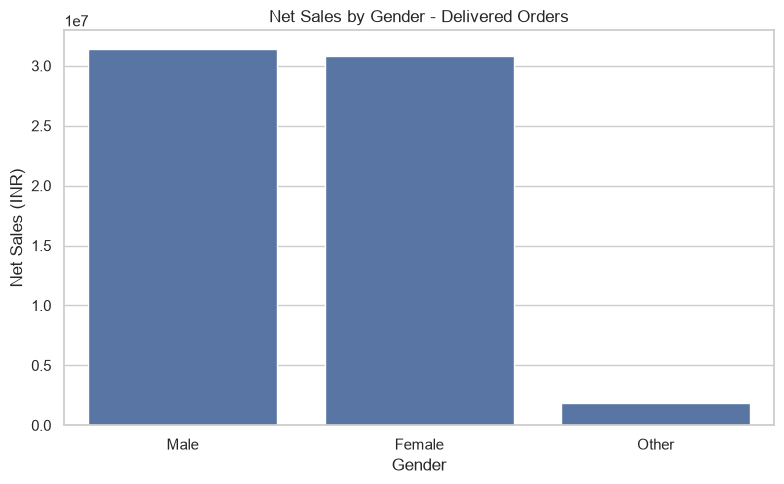

Saved: 06_gender_revenue.png


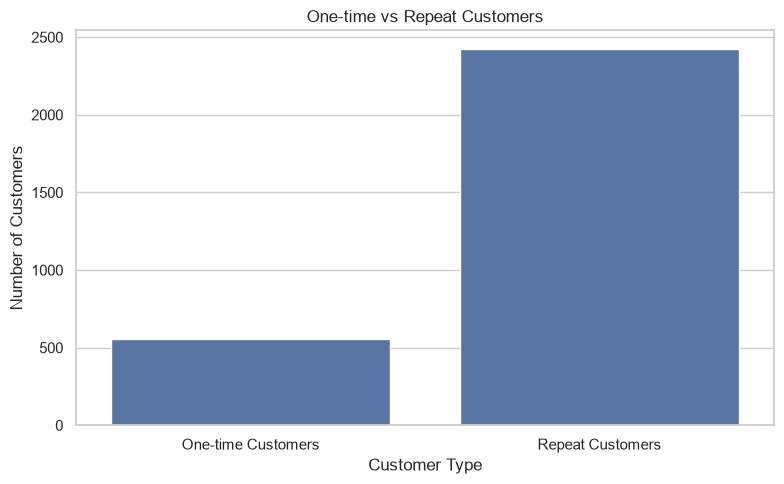

Saved: 07_customer_retention.png


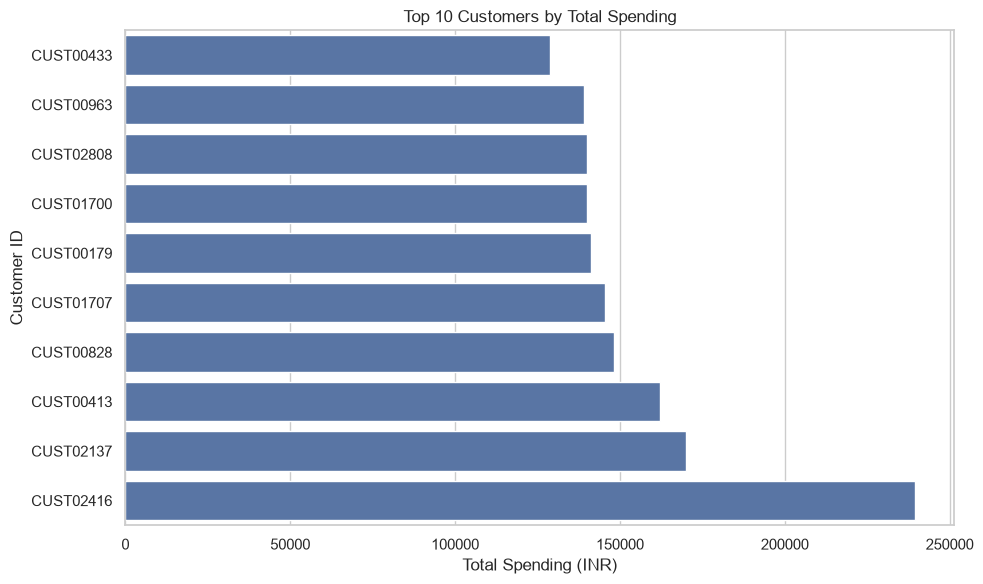

Saved: 08_top_10_customers.png


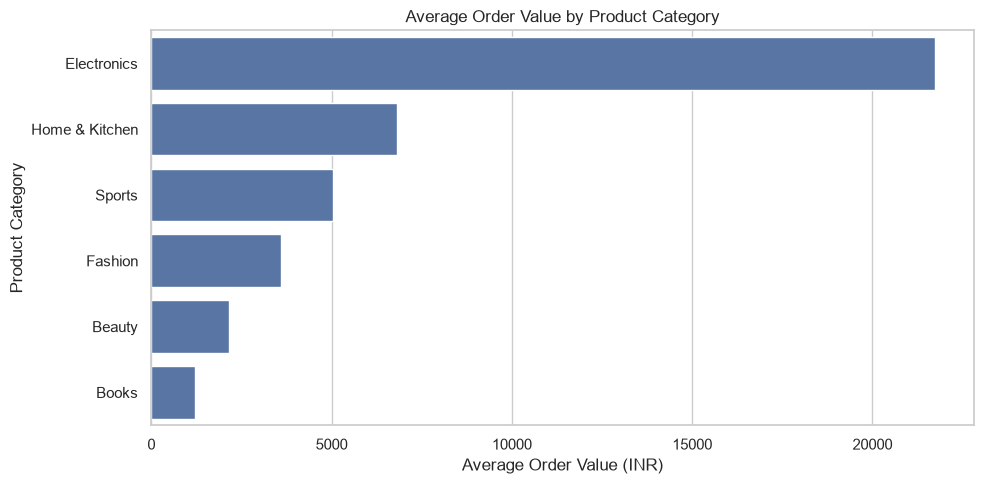

Saved: 09_category_average_order_value.png

All 9 charts have been saved successfully!
Chart folder: ../outputs/eda_charts


In [22]:

import os
import matplotlib.pyplot as plt
import seaborn as sns

# Create folder for saving charts
output_dir = "../outputs/eda_charts"
os.makedirs(output_dir, exist_ok=True)

# Prepare delivered orders
delivered_df = df[df["order_status"] == "Delivered"].copy()

# Helper function to save and display charts
def save_chart(filename):
    plt.tight_layout()
    plt.savefig(
        os.path.join(output_dir, filename),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()
    print(f"Saved: {filename}")


# 1. Monthly delivered sales trend
monthly_sales = (
    delivered_df.groupby(delivered_df["order_date"].dt.to_period("M"))
    ["net_amount_inr"].sum()
)

plt.figure(figsize=(14, 5))
sns.lineplot(x=monthly_sales.index.astype(str), y=monthly_sales.values,
             marker="o")
plt.title("Monthly Net Sales Trend - Delivered Orders")
plt.xlabel("Month")
plt.ylabel("Net Sales (INR)")
plt.xticks(rotation=60)
save_chart("01_monthly_sales_trend.png")


# 2. Order status distribution
status_counts = df["order_status"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=status_counts.index, y=status_counts.values)
plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
save_chart("02_order_status_distribution.png")


# 3. Revenue by product category
category_revenue = (
    delivered_df.groupby("product_category")["net_amount_inr"]
    .sum().sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=category_revenue.values, y=category_revenue.index)
plt.title("Net Sales by Product Category - Delivered Orders")
plt.xlabel("Net Sales (INR)")
plt.ylabel("Product Category")
save_chart("03_category_revenue.png")


# 4. Order count by product category
category_orders = (
    delivered_df.groupby("product_category")["order_id"]
    .count().sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=category_orders.values, y=category_orders.index)
plt.title("Delivered Order Count by Product Category")
plt.xlabel("Number of Orders")
plt.ylabel("Product Category")
save_chart("04_category_order_count.png")


# 5. Revenue by city
city_revenue = (
    delivered_df.groupby("city")["net_amount_inr"]
    .sum().sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=city_revenue.values, y=city_revenue.index)
plt.title("Net Sales by City - Delivered Orders")
plt.xlabel("Net Sales (INR)")
plt.ylabel("City")
save_chart("05_city_revenue.png")


# 6. Revenue by gender
gender_revenue = (
    delivered_df.groupby("gender")["net_amount_inr"]
    .sum().sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=gender_revenue.index, y=gender_revenue.values)
plt.title("Net Sales by Gender - Delivered Orders")
plt.xlabel("Gender")
plt.ylabel("Net Sales (INR)")
save_chart("06_gender_revenue.png")


# 7. Repeat vs one-time customers
customer_type_counts = pd.Series({
    "One-time Customers": len(one_time_customers),
    "Repeat Customers": len(repeat_customers)
})

plt.figure(figsize=(8, 5))
sns.barplot(
    x=customer_type_counts.index,
    y=customer_type_counts.values
)
plt.title("One-time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
save_chart("07_customer_retention.png")


# 8. Top 10 customers by total spending
top_customers = (
    customer_analysis["total_spent"]
    .nlargest(10).sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_customers.values, y=top_customers.index)
plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Total Spending (INR)")
plt.ylabel("Customer ID")
save_chart("08_top_10_customers.png")


# 9. Average order value by category
category_aov = (
    delivered_df.groupby("product_category")["net_amount_inr"]
    .mean().sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=category_aov.values, y=category_aov.index)
plt.title("Average Order Value by Product Category")
plt.xlabel("Average Order Value (INR)")
plt.ylabel("Product Category")
save_chart("09_category_average_order_value.png")


print("\nAll 9 charts have been saved successfully!")
print("Chart folder:", output_dir)


## 8. Key Business Insights

# Key Business Insights

Based on the exploratory data analysis of 10,000 e-commerce orders, the following insights were identified.

### 1. Sales Performance
- Delivered orders generated approximately ₹64.08 lakh in net sales.
- August 2024 recorded the highest monthly delivered-order net sales.
- Monthly sales fluctuated across the two-year period.

### 2. Product Category Performance
- Electronics contributed approximately 58.1% of total delivered-order net sales.
- Home & Kitchen was the second-highest category by net sales.
- Books generated the lowest net sales, but should not be discontinued based on revenue alone. Order volume and profitability should also be considered.

### 3. Order Status
- 85.93% of orders were delivered.
- 9.11% were cancelled.
- 4.96% were returned.
- The business should investigate reasons for cancellations and returns.

### 4. City Performance
- Pune recorded the highest delivered-order net sales in the analysis.
- Marketing investments should consider city-level demand, profitability, customer acquisition cost, and growth potential.

### 5. Customer Analysis
- The dataset contains 2,978 customers with at least one delivered order.
- 2,422 customers were repeat customers.
- The repeat-customer percentage was 81.33%.
- 556 customers placed only one delivered order.

### 6. High-Value Customers
- A small group of customers contributed substantial spending.
- High-spending customers can be studied for personalised offers and loyalty programmes.
- High spending from a single purchase should not automatically be interpreted as customer loyalty.

### 7. Business Recommendations
- Monitor Electronics performance because of its large contribution to net sales.
- Explore opportunities to improve lower-revenue categories.
- Develop customer retention and loyalty programmes.
- Investigate cancelled and returned orders.
- Evaluate marketing performance across cities.
- Monitor monthly sales trends and investigate unusual fluctuations.

### Conclusion
The exploratory analysis provides an understanding of sales performance, product categories, customer purchasing behaviour, and geographical performance. These findings can support business decisions and provide a foundation for the next stage of customer analytics and machine learning.